# <font color="blue">Detección de puntos clave en perros · MobileNetV2 + mapas de calor</font>

**Ciencia de Datos · Procesamiento de Imágenes (avanzado) · Cuaderno 9D**

Objetivo: localizar **24 puntos anatómicos** de un perro (patas, orejas, ojos, nariz, cola…) en una foto,
con aprendizaje por transferencia, y guardar el modelo que usa la app de Streamlit
([`app_streamlit.py`](Trabajo_23_Oct_Puntos_Clave_Streamlit/app_streamlit.py)).

Idea original del cuaderno: *Detección de puntos clave con aprendizaje por transferencia*
(Alfredo Díaz Claro, sobre el trabajo de Sayak Paul y Muhammad Anas Raza). Dataset: **StanfordExtra**
(Biggs et al., ECCV 2020).

## Qué cambia respecto a la versión original (y por qué)

La versión original predecía **48 números** (24 × x, y) tras un pooling global y se entrenaba 25 pasos.
Al medirla en imágenes que el modelo **no vio**, no mejoraba la pose media (error ≈ 20 % de la imagen
igual que predecir siempre el promedio): con tan pocas imágenes, la regresión directa no aprende a localizar.

Este cuaderno corrige eso:

| Problema de la versión original | Corrección |
|---|---|
| Regresión directa de coordenadas (no localiza con ~25 imágenes) | **Mapas de calor**: un mapa de 56×56 por punto, la red conserva la información espacial |
| El volteo horizontal no intercambiaba izquierda/derecha | El volteo **intercambia** las etiquetas (pata izquierda ↔ derecha, ojos, orejas) |
| Los puntos no anotados se entrenaban como si estuvieran en (0, 0) | Su mapa es cero y su peso en la pérdida casi nulo |
| Un punto que sale del cuadro por el aumento seguía contando como visible | Se marca como no visible |
| BatchNorm entrenable con lotes pequeños (desajuste entrenamiento/inferencia) | BatchNorm del backbone en modo inferencia |
| Se evaluaba sobre las mismas imágenes de entrenamiento | **Validación cruzada de 5 pliegues**: el error se mide solo en imágenes no vistas |
| El modelo no se guardaba | Se guarda en `modelos/modelo_puntos_clave.keras` |

> ⚠️ **Límite honesto:** la muestra pública de StanfordExtra tiene **solo 25 imágenes** (4 razas). El dataset
> completo (12 000 imágenes) se solicita a los autores. Con 25 imágenes el modelo es una **demostración del
> pipeline**: funciona en perros parecidos a los de la muestra, no es un detector de producción.

## 1. Entorno

In [1]:
import io, json, os, time, urllib.request, zipfile

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
try:                                   # con PyTorch se entrena en la GPU (CUDA); Colab ya lo trae
    import torch
    os.environ.setdefault("KERAS_BACKEND", "torch")
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no hay GPU (se usa CPU)")
except ImportError:
    print("Sin PyTorch: Keras usará TensorFlow")

import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers, ops
from PIL import Image, ImageEnhance

print("Keras", keras.__version__, "· backend:", keras.backend.backend())

GPU: NVIDIA GeForce RTX 4060


Keras 3.15.1 · backend: torch


## 2. Datos: muestra pública de StanfordExtra

El cuaderno descarga el repositorio (25 imágenes anotadas con 24 puntos). Cada punto es `[x, y, visibilidad]`.
Detalle importante: en esta muestra los puntos **20-23** (ojo izquierdo, ojo derecho, cruz y garganta)
**nunca vienen anotados**; el modelo no tiene señal para aprenderlos.

In [2]:
SE_DIR = "StanfordExtra-master"
if not os.path.exists(SE_DIR):
    url = "https://github.com/benjiebob/StanfordExtra/archive/refs/heads/master.zip"
    with zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read())) as z:
        z.extractall(".")
JSON_PATH = os.path.join(SE_DIR, "StanfordExtra_sample.json")
MODEL_PATH = os.path.join("modelos", "modelo_puntos_clave.keras")
CV_PATH = os.path.join("resultados", "validacion_cruzada.json")

IMG_SIZE = 224
HM = 56                         # lado del mapa de calor (stride 4)
NUM_KP = 24
VARIANTS = 40                   # aumentos por imagen
EPOCHS = 50
BATCH = 16
LR = 1e-3
SIGMA = 2.0                     # ancho de la gaussiana objetivo (en celdas del mapa)
UNFREEZE_FROM = "block_13_expand"
FOLDS = 5
SEED = 0

# Pares simétricos: al voltear la imagen hay que intercambiar las etiquetas
SWAP = {0: 6, 1: 7, 2: 8, 3: 9, 4: 10, 5: 11,
        6: 0, 7: 1, 8: 2, 9: 3, 10: 4, 11: 5,
        14: 15, 15: 14, 18: 19, 19: 18, 20: 21, 21: 20}
PERM = np.array([SWAP.get(i, i) for i in range(NUM_KP)])

keras.utils.set_random_seed(SEED)
g = np.random.default_rng(SEED)

In [3]:
def cargar(entry):
    """Imagen RGB 224×224, coordenadas normalizadas (sin recortar) y visibilidad."""
    img = (Image.open(os.path.join(SE_DIR, "sample_imgs", entry["img_path"]))
           .convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    w, h = entry["img_width"], entry["img_height"]
    kps = np.array([[p[0] / w, p[1] / h] for p in entry["joints"]], dtype="float32")
    vis = np.array([1.0 if p[2] > 0 else 0.0 for p in entry["joints"]], dtype="float32")
    return np.array(img, dtype="uint8"), kps, vis


datos = json.load(open(JSON_PATH, encoding="utf-8"))
imgs, kps, vis = (np.stack(z) for z in zip(*(cargar(e) for e in datos)))
gt = np.clip(kps, 0, 1)
n = len(imgs)
print(f"{n} imágenes {imgs.shape[1:]} · puntos anotados por imagen: {vis.sum(1).mean():.1f} de 24")
print("puntos que NUNCA se anotan:", [j for j in range(NUM_KP) if vis[:, j].sum() == 0])

25 imágenes (224, 224, 3) · puntos anotados por imagen: 15.3 de 24
puntos que NUNCA se anotan: [20, 21, 22, 23]


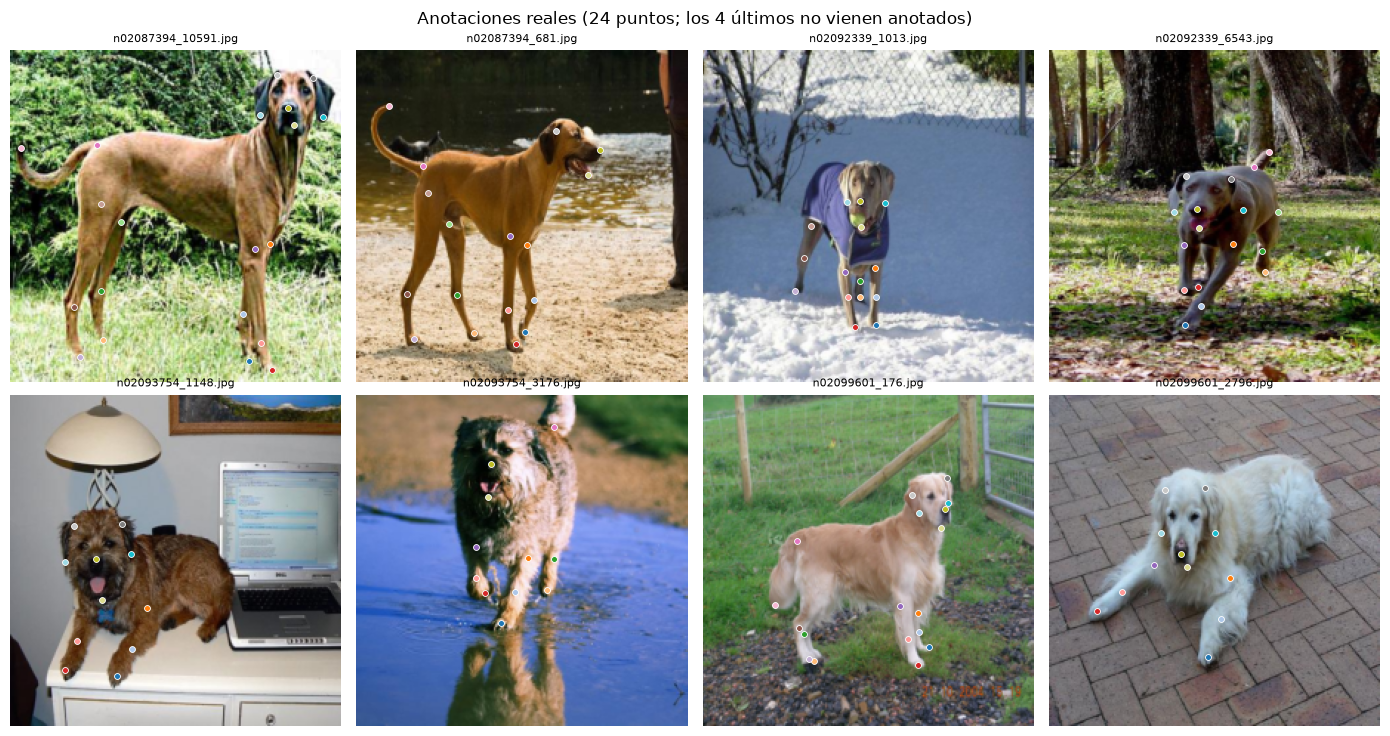

In [4]:
cmap = plt.get_cmap("tab20")

def dibujar_puntos(ax, img, k, v, titulo="", tam=18):
    ax.imshow(img); ax.axis("off"); ax.set_title(titulo, fontsize=8)
    for j in range(NUM_KP):
        if v[j] > 0:
            ax.scatter(k[j, 0] * IMG_SIZE, k[j, 1] * IMG_SIZE, s=tam, color=cmap(j % 20),
                       edgecolors="white", linewidths=0.6)

fig, axs = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axs.ravel(), range(0, n, 3)):
    dibujar_puntos(ax, imgs[i], gt[i], vis[i], datos[i]["img_path"].split("/")[-1])
plt.suptitle("Anotaciones reales (24 puntos; los 4 últimos no vienen anotados)"); plt.tight_layout(); plt.show()

## 3. Aumento de datos

Con 25 imágenes el aumento es imprescindible. Cada imagen genera `VARIANTS` versiones con rotación, escala,
traslación, **volteo horizontal con intercambio izquierda/derecha** y cambios de brillo, contraste y color.
Si el aumento deja un punto fuera de la imagen, deja de contar como visible.

In [5]:
def aumentar(img, kps, vis, g):
    """Rotación ±15°, escala 0.8-1.2, traslación ±6 %, volteo L/R y fotometría."""
    S = IMG_SIZE
    ang = np.deg2rad(g.uniform(-15, 15))
    s = g.uniform(0.8, 1.2)
    t = g.uniform(-0.06, 0.06, 2) * S
    c = np.array([S / 2, S / 2])
    R = np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]]) * s
    A = np.eye(3)
    A[:2, :2] = R
    A[:2, 2] = c + t - R @ c

    if g.random() < 0.5:                                # volteo + intercambio L/R
        F = np.array([[-1.0, 0, S - 1], [0, 1.0, 0], [0, 0, 1]])
        A = F @ A
        kps, vis = kps[PERM].copy(), vis[PERM].copy()

    Ai = np.linalg.inv(A)                               # PIL usa la transformada inversa
    im = Image.fromarray(img).transform(
        (S, S), Image.AFFINE, (Ai[0, 0], Ai[0, 1], Ai[0, 2], Ai[1, 0], Ai[1, 1], Ai[1, 2]),
        resample=Image.BILINEAR)

    ph = np.concatenate([kps * S, np.ones((NUM_KP, 1))], 1) @ A.T
    k2 = (ph[:, :2] / S).astype("float32")
    vis = vis * ((k2 >= 0) & (k2 < 1)).all(1)           # fuera de cuadro => no visible

    im = ImageEnhance.Brightness(im).enhance(g.uniform(0.7, 1.3))
    im = ImageEnhance.Contrast(im).enhance(g.uniform(0.75, 1.25))
    im = ImageEnhance.Color(im).enhance(g.uniform(0.7, 1.3))
    return np.array(im, dtype="uint8"), np.clip(k2, 0, 1), vis


def mapas_objetivo(kps, vis):
    """(n, 24, 2) + (n, 24) -> (n, 56, 56, 24): gaussianas en los puntos visibles."""
    ys, xs = np.mgrid[0:HM, 0:HM]
    T = np.zeros((len(kps), HM, HM, NUM_KP), "float32")
    for n in range(len(kps)):
        for j in range(NUM_KP):
            if vis[n, j] > 0:
                cx, cy = kps[n, j] * HM - 0.5
                T[n, :, :, j] = np.exp(-((xs - cx) ** 2 + (ys - cy) ** 2) / (2 * SIGMA ** 2))
    return T


def generar(imgs, kps, vis, idx, g, variantes):
    X, K, V = [], [], []
    for i in idx:
        for _ in range(variantes):
            a, b, c = aumentar(imgs[i], kps[i], vis[i], g)
            X.append(a), K.append(b), V.append(c)
    X, K, V = np.stack(X), np.stack(K), np.stack(V).astype("float32")
    T = mapas_objetivo(K, V)
    peso = np.broadcast_to(V[:, None, None, :], T.shape)   # 1 donde el punto está anotado
    return X, np.concatenate([T, peso], -1).astype("float32")

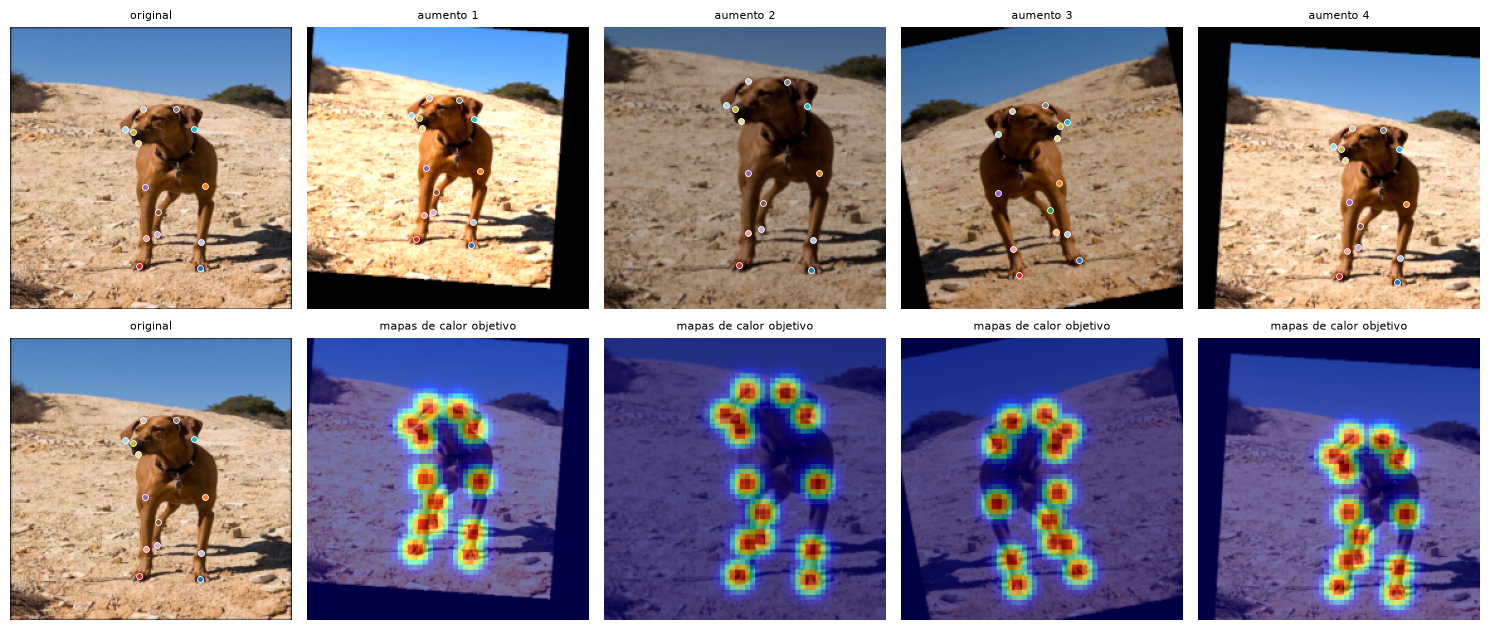

In [6]:
# Comprobación visual: tras un volteo, el punto 0 (pata delantera izquierda) pasa a llamarse 6 (derecha)
fig, axs = plt.subplots(2, 5, figsize=(15, 6.5))
dibujar_puntos(axs[0, 0], imgs[2], gt[2], vis[2], "original")
dibujar_puntos(axs[1, 0], imgs[2], gt[2], vis[2], "original")
for c in range(1, 5):
    a, b, v = aumentar(imgs[2], kps[2], vis[2], g)
    dibujar_puntos(axs[0, c], a, b, v, f"aumento {c}")
    T = mapas_objetivo(b[None], v[None])[0].max(-1)           # mapa de calor objetivo (suma de los puntos)
    axs[1, c].imshow(a); axs[1, c].imshow(np.kron(T, np.ones((4, 4))), alpha=0.55, cmap="jet"); axs[1, c].axis("off")
    axs[1, c].set_title("mapas de calor objetivo", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Modelo: MobileNetV2 + cabeza de mapas de calor

```
Imagen 224×224×3 (uint8)
  → preprocess_input (MobileNetV2)
  → MobileNetV2 · ImageNet           (solo el último bloque entrenable, BatchNorm congelado)  → 7×7×1280
  → 3 × [Conv2DTranspose(128, 4, stride 2) → BatchNorm → ReLU]                              → 56×56×128
  → Conv2D 1×1 (24)                                                                          → 56×56×24
```

Cada canal es el mapa de calor de un punto. La **posición** del punto es el pico del mapa (refinada con un
centroide local) y la **altura del pico** es la confianza de que el punto se vea.

**Pérdida:** error cuadrático entre el mapa predicho y una gaussiana centrada en el punto real. El pico pesa
30 veces más que el fondo (si no, la red aprende a predecir todo cero) y los puntos no anotados casi no cuentan.

In [7]:
def construir_modelo():
    """MobileNetV2 (ImageNet) + 3 deconvoluciones -> 24 mapas de calor de 56×56."""
    base = keras.applications.MobileNetV2(weights="imagenet", include_top=False,
                                          input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    nombres = [l.name for l in base.layers]
    for l in base.layers[nombres.index(UNFREEZE_FROM):]:
        if not isinstance(l, layers.BatchNormalization):   # BN siempre en modo inferencia
            l.trainable = True

    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3), dtype="uint8")
    x = keras.applications.mobilenet_v2.preprocess_input(layers.Rescaling(1.0)(inp))
    x = base(x)
    for _ in range(3):                                      # 7 -> 14 -> 28 -> 56
        x = layers.Conv2DTranspose(128, 4, strides=2, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    out = layers.Conv2D(NUM_KP, 1, name="mapas_de_calor")(x)
    return keras.Model(inp, out, name="detector_puntos_clave")


def perdida(y_true, y_pred):
    """MSE de mapas de calor; el pico pesa más que el fondo y los puntos sin anotar casi no cuentan."""
    t, w = y_true[..., :NUM_KP], y_true[..., NUM_KP:]
    return ops.mean(ops.square(y_pred - t) * (1 + 30 * t) * (0.1 + 0.9 * w)) * 100


def entrenar(X, Y, epocas):
    model = construir_modelo()
    model.compile(loss=perdida, optimizer=keras.optimizers.AdamW(LR, weight_decay=1e-4))
    cb = keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=4, min_lr=5e-5)
    model.fit(X, Y, batch_size=BATCH, epochs=epocas, verbose=2, callbacks=[cb])
    return model


construir_modelo().summary()

Model: "detector_puntos_clave"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 128)    │     2,621,440 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 128)    │       262,144 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 56, 56, 128)    │       262,144 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mapas_de_calor (Conv2D)         │ (None, 56, 56, 24)     │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,408,344 (20.63 MB)

 Trainable params: 4,812,952 (18.36 MB)

 Non-trainable params: 595,392 (2.27 MB)

## 5. Validación cruzada (5 pliegues)

Se entrena 5 veces dejando fuera 5 imágenes distintas cada vez, y el error se mide **solo en las imágenes
que quedaron fuera**. Es la única cifra honesta de generalización. Se compara con una referencia trivial:
**predecir siempre la pose media** del conjunto de entrenamiento.

Error = distancia media entre el punto predicho y el real, en % del tamaño de la imagen (solo puntos anotados).

In [8]:
def decodificar(mapas):
    """(n, 56, 56, 24) -> kps (n, 24, 2) en [0,1] y pico (n, 24).

    Posición = centroide ponderado alrededor del máximo (precisión sub-celda).
    """
    n = len(mapas)
    kps = np.zeros((n, NUM_KP, 2), "float32")
    pico = np.zeros((n, NUM_KP), "float32")
    for a in range(n):
        for j in range(NUM_KP):
            h = mapas[a, :, :, j]
            r, c = np.unravel_index(h.argmax(), h.shape)
            pico[a, j] = h[r, c]
            r0, r1, c0, c1 = max(r - 2, 0), min(r + 3, HM), max(c - 2, 0), min(c + 3, HM)
            w = np.clip(h[r0:r1, c0:c1], 0, None) + 1e-9
            yy, xx = np.mgrid[r0:r1, c0:c1]
            kps[a, j] = [((xx * w).sum() / w.sum() + 0.5) / HM,
                         ((yy * w).sum() / w.sum() + 0.5) / HM]
    return kps, pico


def error_pct(pred, gt, vis):
    d = np.linalg.norm(pred - gt, axis=-1)
    return float((d * vis).sum() / vis.sum() * 100)

In [9]:
errs, base_errs, picos_vis, picos_no = [], [], [], []
pred_cv = np.zeros((n, NUM_KP, 2), "float32")                 # predicción de cada imagen cuando estuvo FUERA
for k in range(FOLDS):
    val = np.arange(n)[np.arange(n) % FOLDS == k]
    tr = np.array([i for i in range(n) if i not in val])
    t0 = time.time()
    X, Y = generar(imgs, kps, vis, tr, g, VARIANTS)
    model = entrenar(X, Y, EPOCHS)
    pk, pico = decodificar(np.asarray(model.predict(imgs[val], verbose=0)))
    pred_cv[val] = pk
    media = (gt[tr] * vis[tr][..., None]).sum(0) / np.maximum(vis[tr].sum(0)[:, None], 1)
    errs.append(error_pct(pk, gt[val], vis[val]))
    base_errs.append(error_pct(np.broadcast_to(media, pk.shape), gt[val], vis[val]))
    sup = np.arange(20)
    picos_vis += list(pico[:, sup][vis[val][:, sup] > 0]); picos_no += list(pico[:, sup][vis[val][:, sup] == 0])
    print(f"[pliegue {k + 1}/{FOLDS}] error en no vistas {errs[-1]:.2f} % | pose media {base_errs[-1]:.2f} % | {time.time() - t0:.0f}s")
    keras.backend.clear_session()

Epoch 1/50


50/50 - 5s - 100ms/step - loss: 10.0780 - learning_rate: 0.0010


Epoch 2/50


50/50 - 3s - 55ms/step - loss: 4.0570 - learning_rate: 0.0010


Epoch 3/50


...

Epoch 49/50


50/50 - 3s - 53ms/step - loss: 0.8773 - learning_rate: 0.0010


Epoch 50/50


50/50 - 3s - 53ms/step - loss: 0.9215 - learning_rate: 0.0010


[pliegue 5/5] error en no vistas 6.94 % | pose media 16.86 % | 137s


{
  "error_no_vistas_pct": 8.718895149230956,
  "error_por_pliegue_pct": [
    10.708,
    7.651,
    7.964,
    10.331,
    6.941
  ],
  "baseline_pose_media_pct": 19.124715423583986,
  "umbral_pico_visibilidad": 0.19,
  "acierto_visibilidad_pct": 77.0,
  "pliegues": 5,
  "epocas": 50,
  "variantes_por_imagen": 40
}


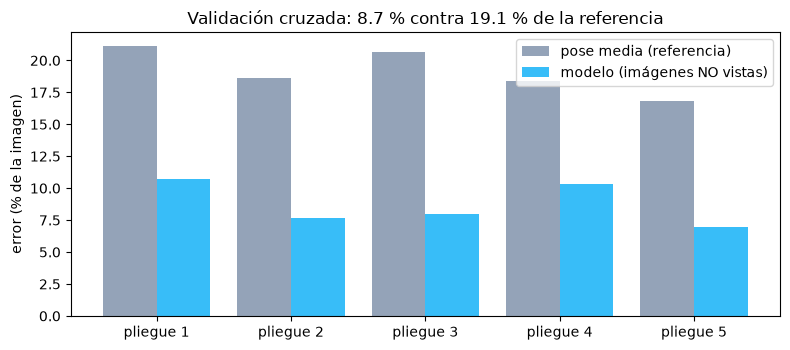

In [10]:
# umbral de visibilidad: el pico del mapa que mejor separa puntos anotados de no anotados
cand = np.linspace(0.05, 0.9, 86)
pv, pn = np.array(picos_vis), np.array(picos_no)
acc = [((pv >= u).sum() + (pn < u).sum()) / (len(pv) + len(pn)) for u in cand]
resumen = {
    "error_no_vistas_pct": float(np.mean(errs)),
    "error_por_pliegue_pct": [round(e, 3) for e in errs],
    "baseline_pose_media_pct": float(np.mean(base_errs)),
    "umbral_pico_visibilidad": round(float(cand[int(np.argmax(acc))]), 3),
    "acierto_visibilidad_pct": round(100 * max(acc), 2),
    "pliegues": FOLDS, "epocas": EPOCHS, "variantes_por_imagen": VARIANTS,
}
os.makedirs("resultados", exist_ok=True)
json.dump(resumen, open(CV_PATH, "w", encoding="utf-8"), indent=2)
print(json.dumps(resumen, indent=2))

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(FOLDS); ax.bar(x - 0.2, base_errs, 0.4, label="pose media (referencia)", color="#94a3b8")
ax.bar(x + 0.2, errs, 0.4, label="modelo (imágenes NO vistas)", color="#38bdf8")
ax.set_xticks(x); ax.set_xticklabels([f"pliegue {i + 1}" for i in x]); ax.set_ylabel("error (% de la imagen)")
ax.set_title(f"Validación cruzada: {np.mean(errs):.1f} % contra {np.mean(base_errs):.1f} % de la referencia"); ax.legend()
plt.tight_layout(); plt.show()

### Predicciones sobre imágenes que el modelo **no vio**

Cada imagen se predice con el modelo del pliegue en que quedó fuera. Verde = anotación real, color = predicción.

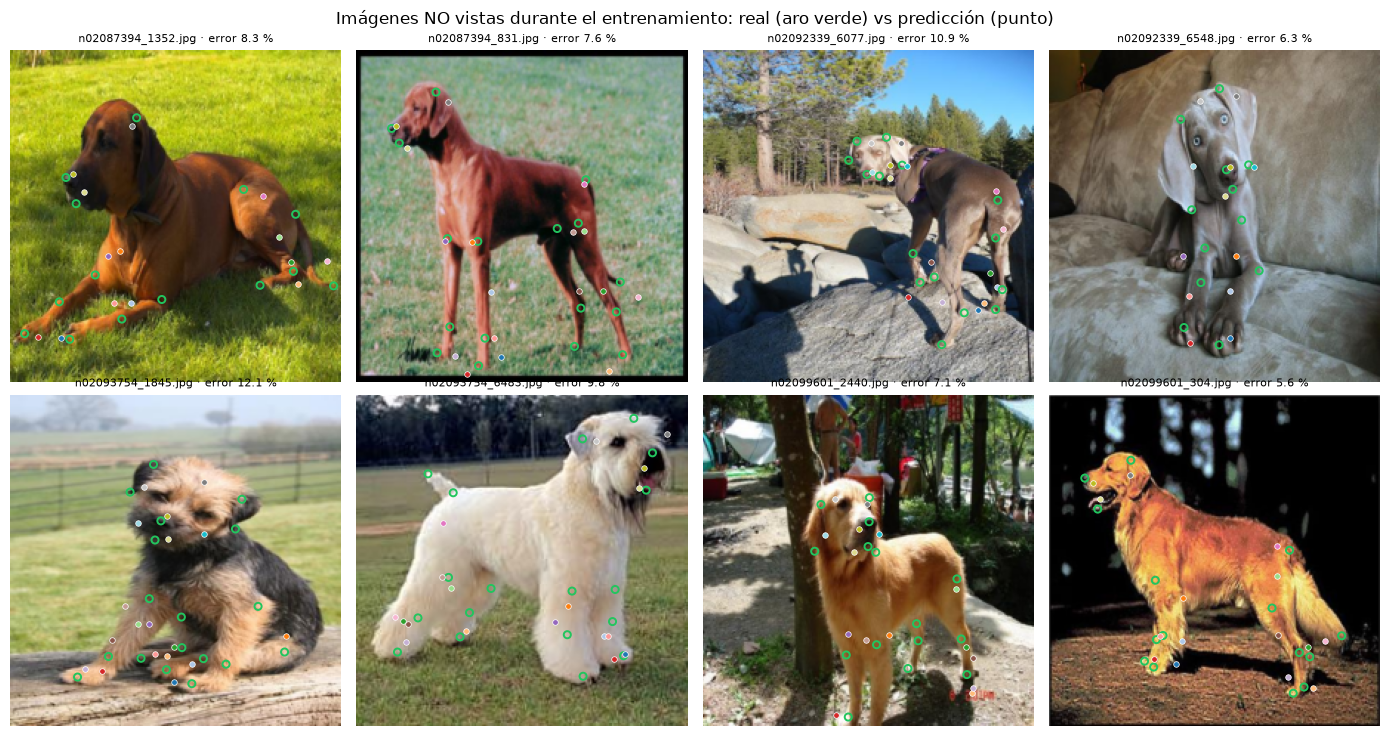

In [11]:
fig, axs = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, i in zip(axs.ravel(), range(1, n, 3)):
    ax.imshow(imgs[i]); ax.axis("off")
    for j in range(20):
        if vis[i, j] > 0:
            ax.scatter(*(gt[i, j] * IMG_SIZE), s=26, facecolors="none", edgecolors="#22c55e", linewidths=1.4)
            ax.scatter(*(pred_cv[i, j] * IMG_SIZE), s=16, color=cmap(j % 20), edgecolors="white", linewidths=0.5)
    ax.set_title(f"{datos[i]['img_path'].split('/')[-1]} · error {error_pct(pred_cv[i:i+1], gt[i:i+1], vis[i:i+1]):.1f} %", fontsize=8)
plt.suptitle("Imágenes NO vistas durante el entrenamiento: real (aro verde) vs predicción (punto)"); plt.tight_layout(); plt.show()

## 6. Modelo final y guardado

Se entrena con las **25 imágenes** y se guarda en `modelos/modelo_puntos_clave.keras`, que es el archivo que carga
la app. El error sobre estas mismas imágenes es solo una referencia (el modelo las vio); la cifra de
generalización es la de la validación cruzada.

In [12]:
X, Y = generar(imgs, kps, vis, np.arange(n), g, VARIANTS)
model = entrenar(X, Y, EPOCHS)
pk, _ = decodificar(np.asarray(model.predict(imgs, verbose=0)))
print(f"error sobre las imágenes de entrenamiento (referencia): {error_pct(pk, gt, vis):.2f} %")

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
limpio = construir_modelo()                        # sin el estado del optimizador (22 MB, no 60)
limpio.set_weights(model.get_weights())
limpio.save(MODEL_PATH)
print(f"modelo guardado en {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

Epoch 1/50


63/63 - 6s - 88ms/step - loss: 7.5408 - learning_rate: 0.0010


Epoch 2/50


63/63 - 3s - 55ms/step - loss: 3.7240 - learning_rate: 0.0010


Epoch 3/50


...

63/63 - 3s - 55ms/step - loss: 0.6463 - learning_rate: 5.0000e-04


Epoch 50/50


63/63 - 3s - 55ms/step - loss: 0.6213 - learning_rate: 5.0000e-04


error sobre las imágenes de entrenamiento (referencia): 2.21 %


modelo guardado en modelos\modelo_puntos_clave.keras (22.3 MB)


## 7. Conclusiones

* Pasar de **regresión directa** a **mapas de calor** es lo que hace que el modelo localice: en imágenes no vistas el
  error baja de ≈ 20 % (sin mejora sobre la pose media) a ≈ 9 % (8,7 %).
* Las correcciones de datos (volteo L/R, puntos no anotados, visibilidad tras el aumento) evitan etiquetas
  contradictorias que la versión original entrenaba sin saberlo.
* **El límite es el dataset**: 25 imágenes de 4 razas. Para un detector real hay que entrenar con StanfordExtra
  completo (12 000 imágenes, se solicita a los autores): en Colab con GPU basta ejecutar este mismo cuaderno
  apuntando `JSON_PATH` al JSON completo.
* **Siguiente paso:** `streamlit run app_streamlit.py` carga el modelo guardado y dibuja los puntos y el contorno
  (envolvente suavizada de los puntos visibles).